In [16]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from pathlib import Path

In [17]:
path = "/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2025-12-09_12-32-16"
path = Path(path) / 'logs'

# Metrics (Overall)


In [ ]:
test_data = pd.read_csv(path / 'test_metrics_per_graph.csv')
train_data = pd.read_csv(path / 'train_metrics_per_graph.csv')
print(test_data.head())


   epoch  dataset_name         loss           mse           mae          rmse  \
0      1     wn18rr_v4    13.135159  1.978225e+16  1.241594e+07  1.406494e+08   
1      1          lubm    72.509084  6.920969e+36  3.182632e+17  2.630774e+18   
2      1      wikidata  2099.772655  1.922627e+76  1.296675e+37  1.386588e+38   
3      1          swdf   257.828831  4.334699e+29  1.408283e+14  6.583843e+14   
4      1  fb237_v4_ind    41.222832  1.005553e+17  8.538290e+07  3.171046e+08   

        q_error  
0  2.601444e+03  
1  3.888018e+11  
2  8.564245e+33  
3  9.855327e+08  
4  1.510665e+05  


# Metric Visualizations

Separate plots for each metric, showing test and train data in different figures.

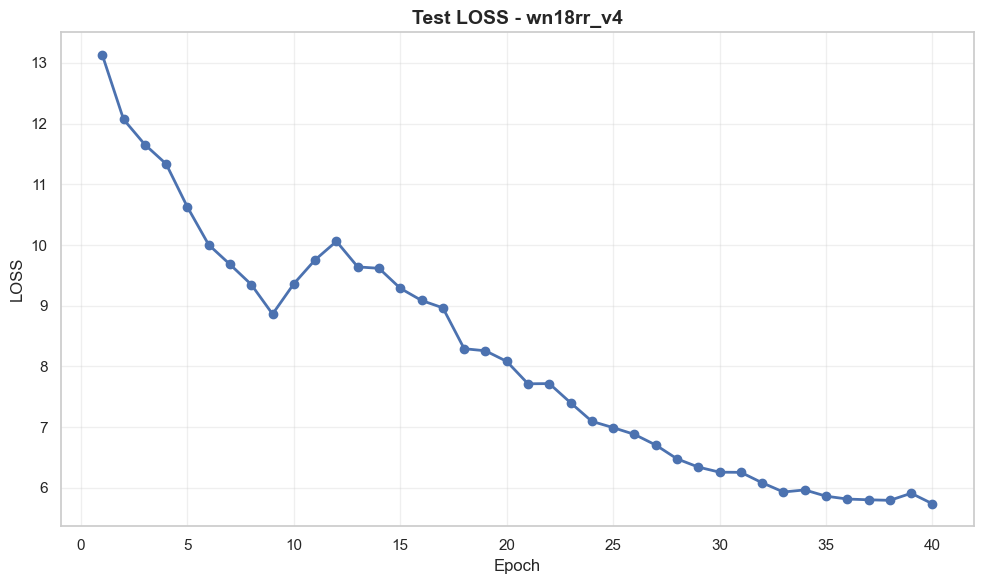

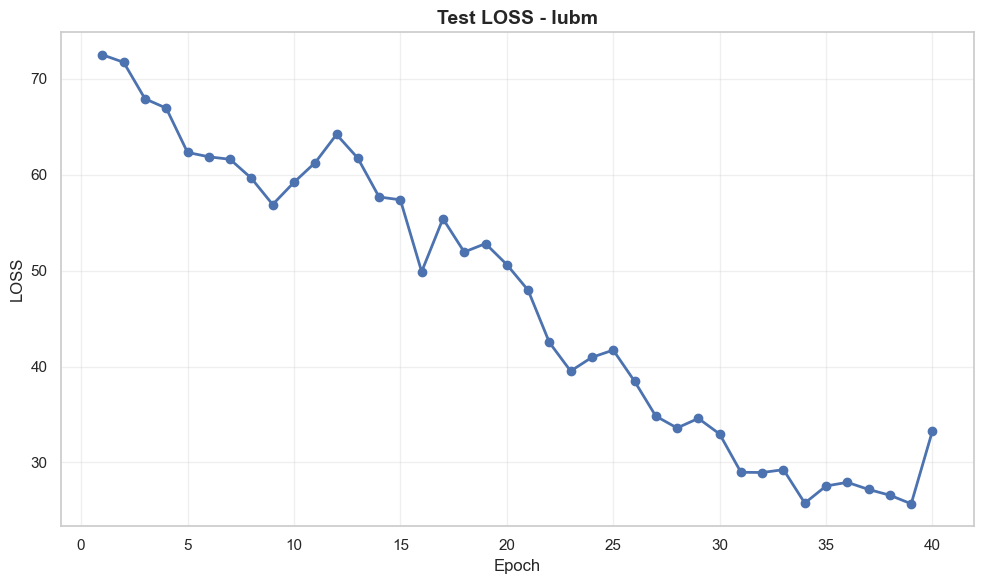

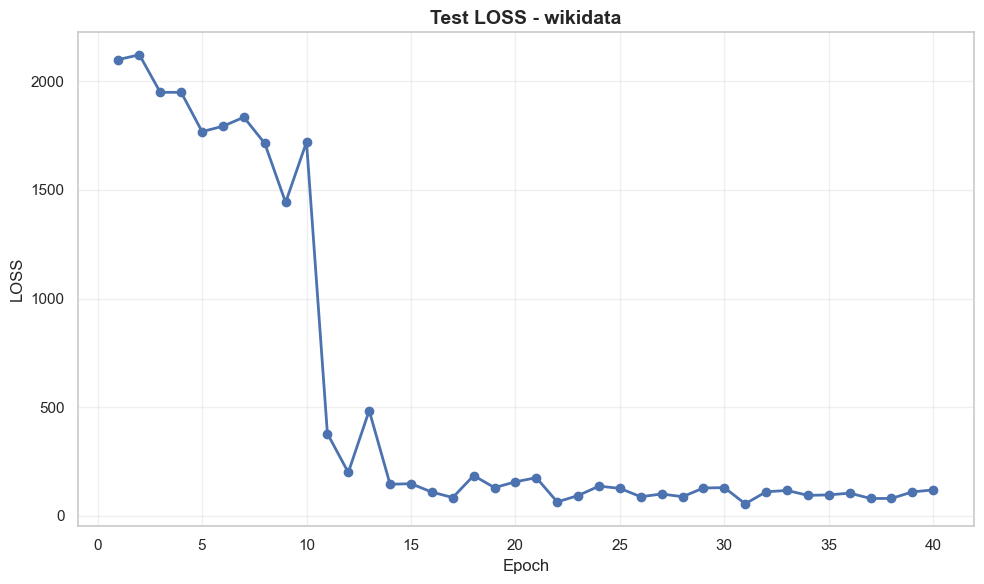

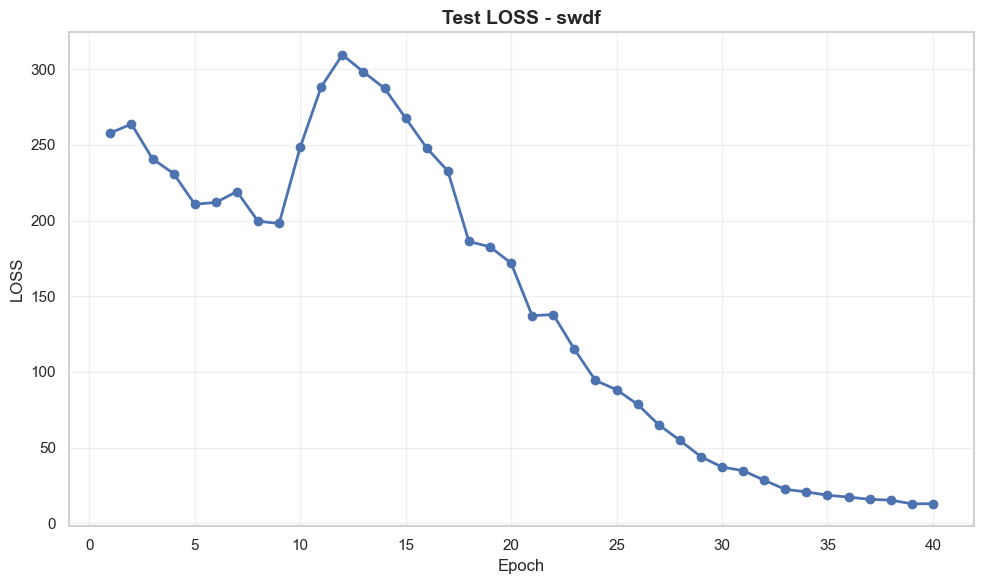

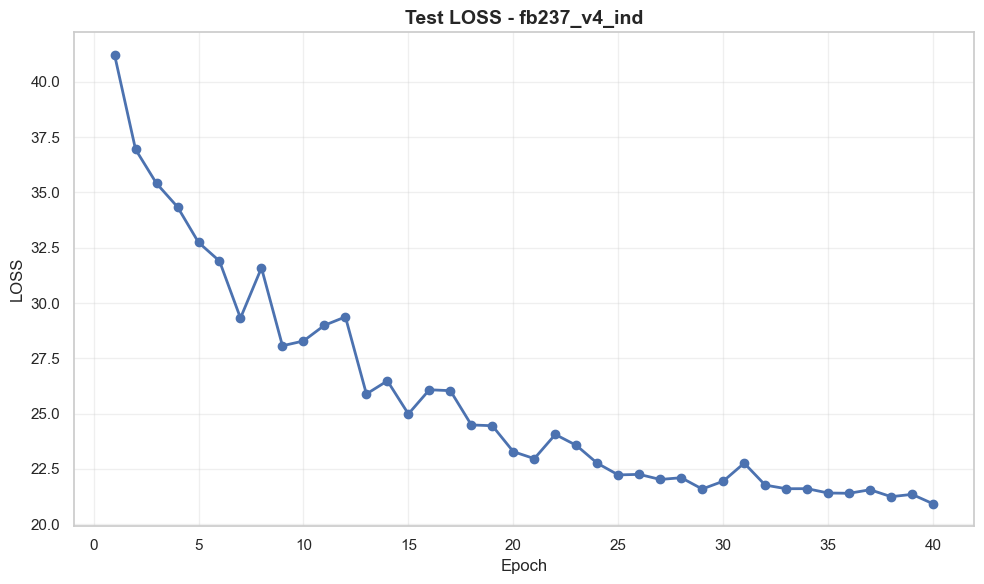

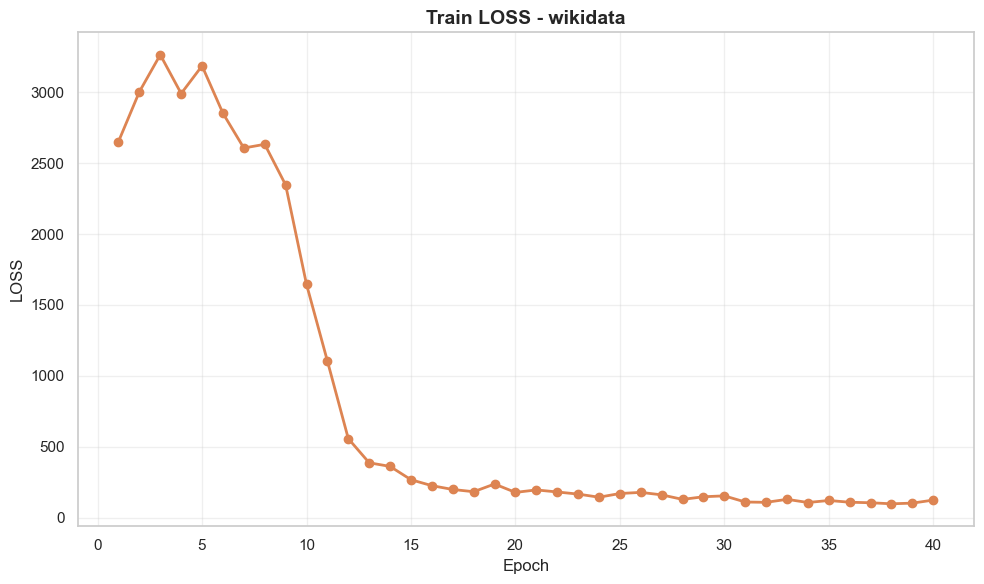

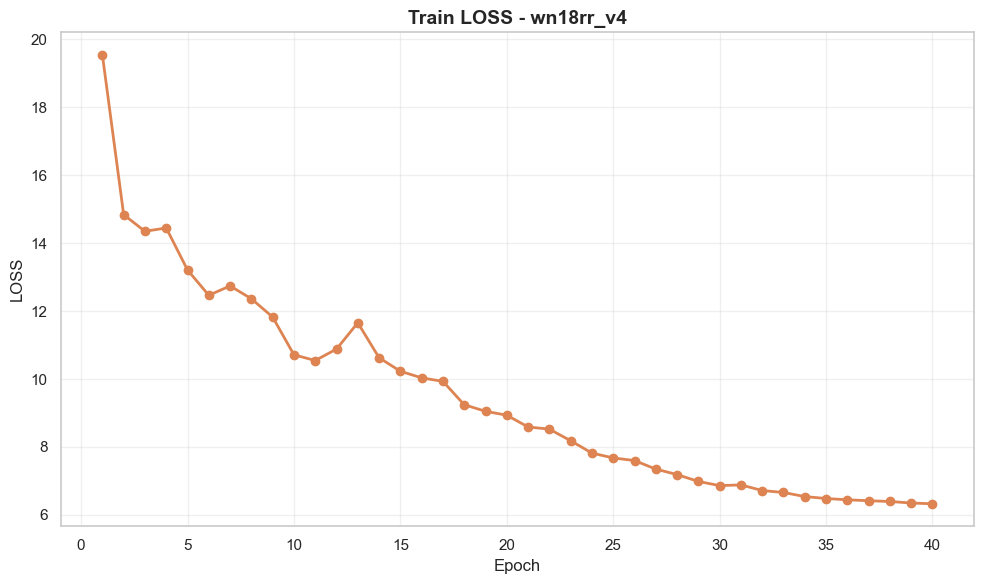

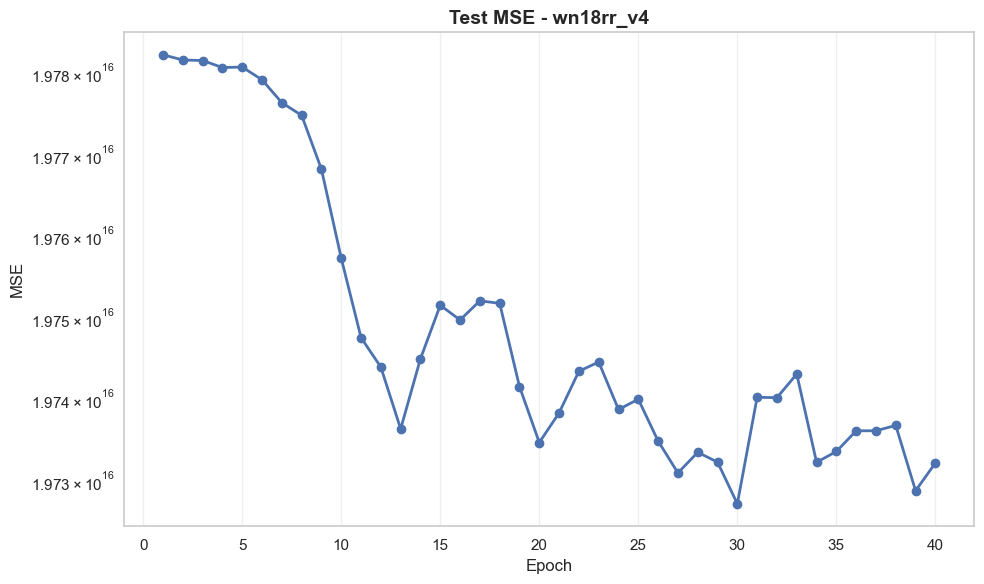

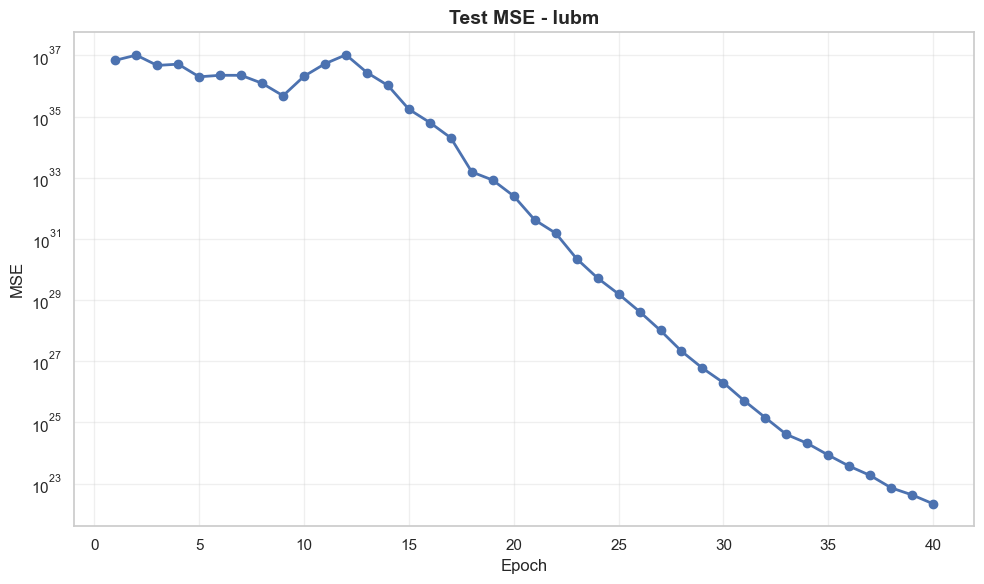

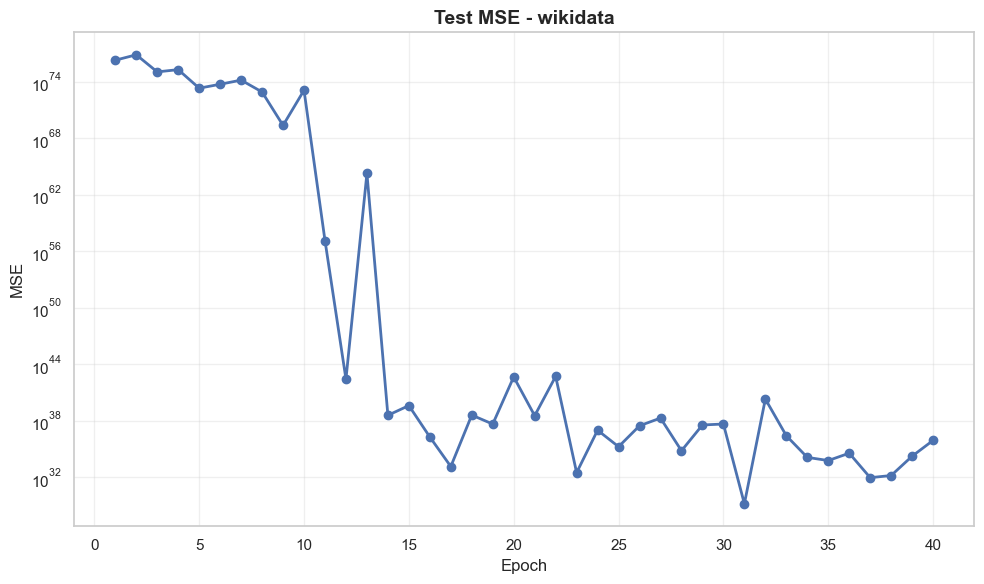

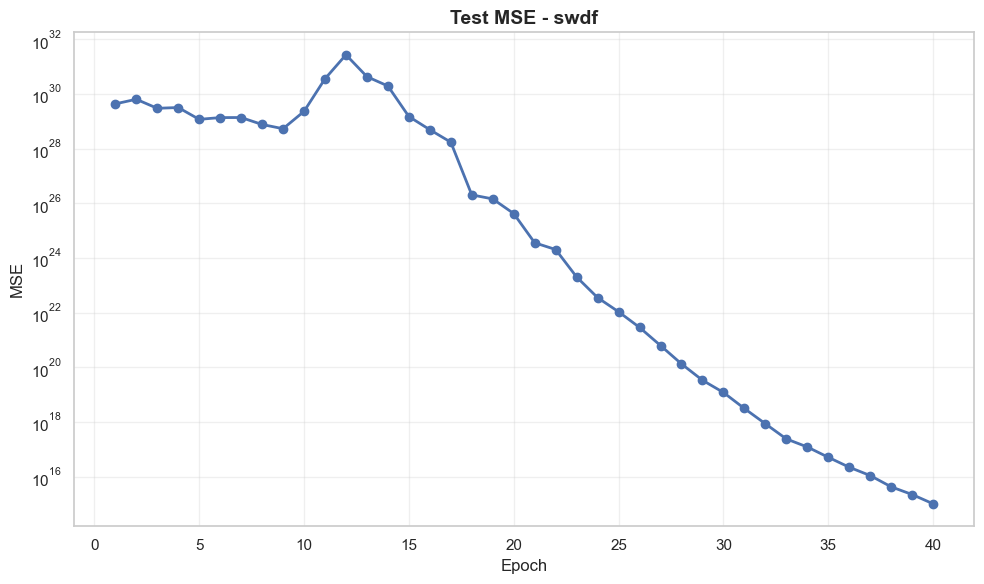

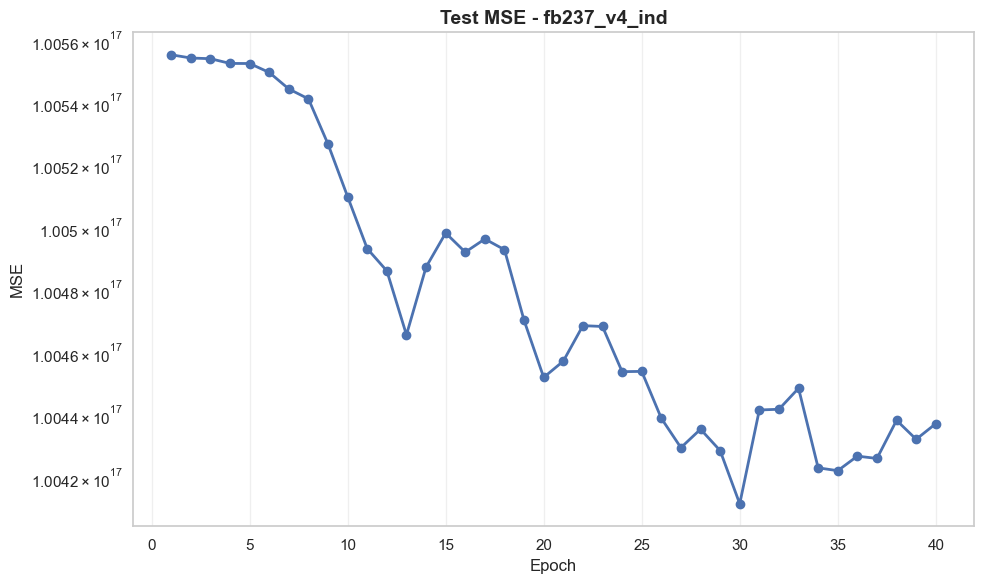

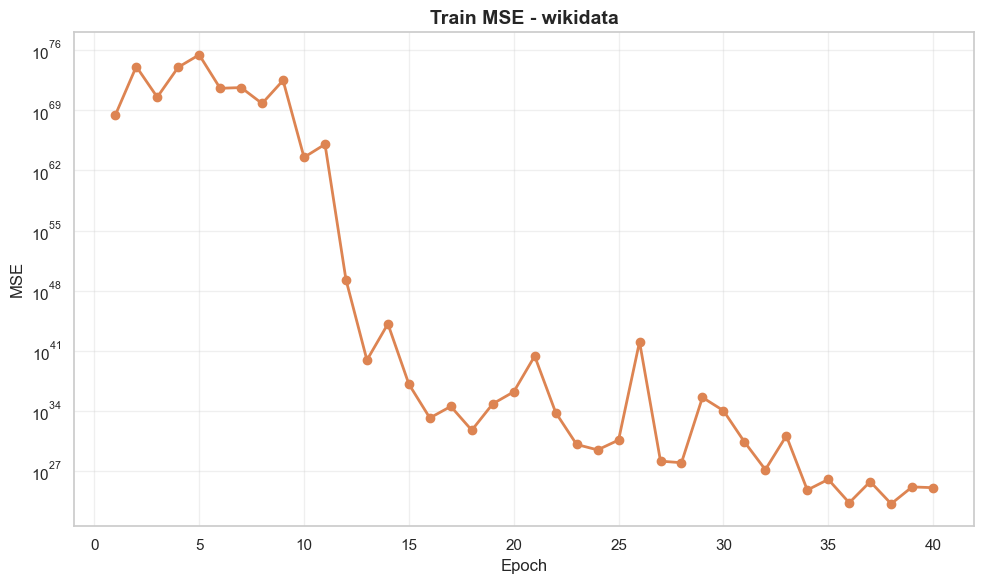

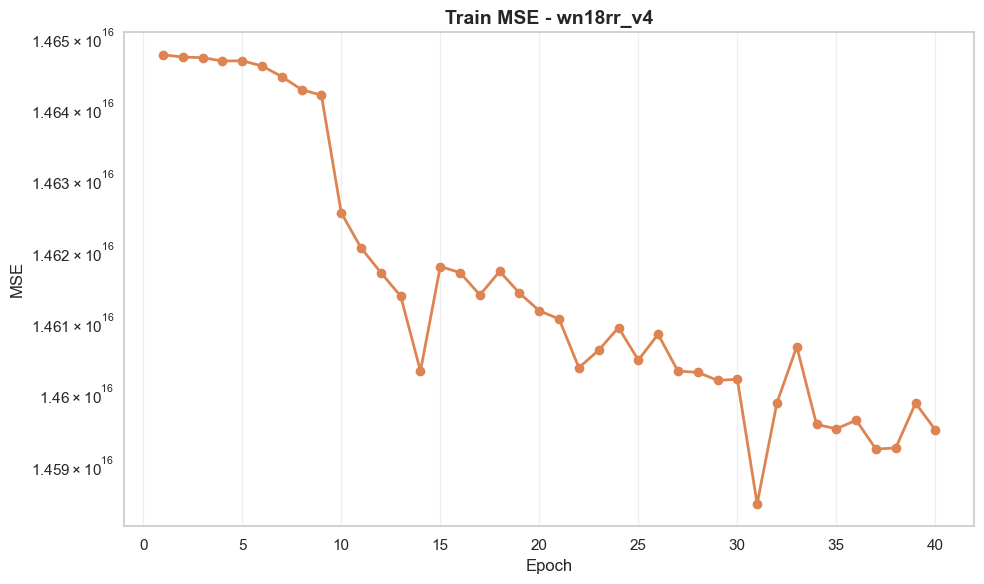

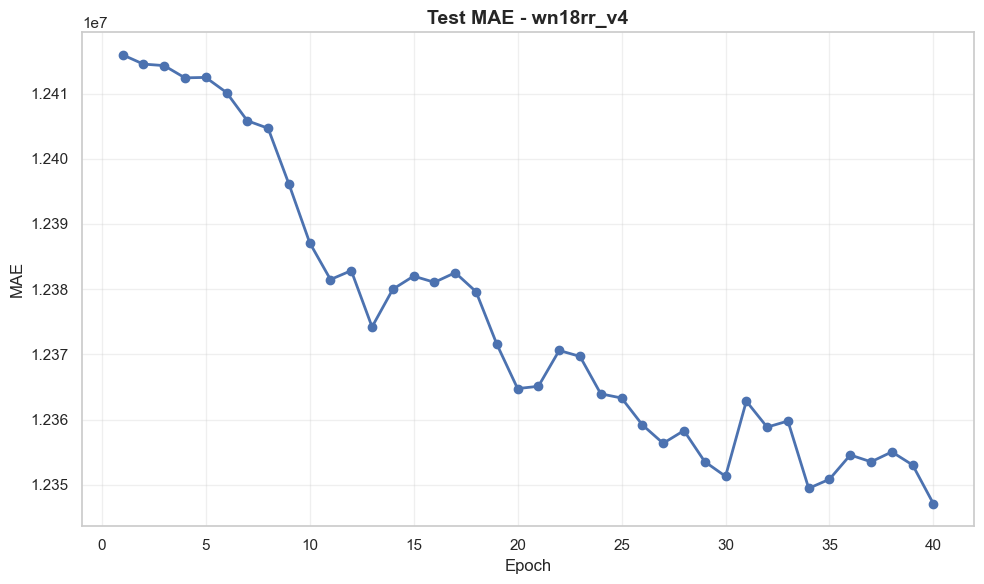

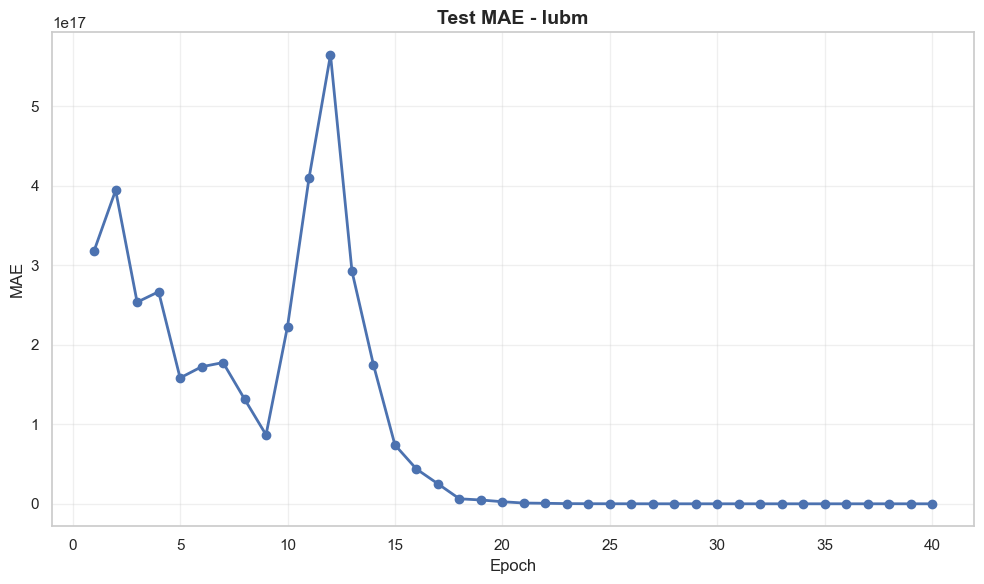

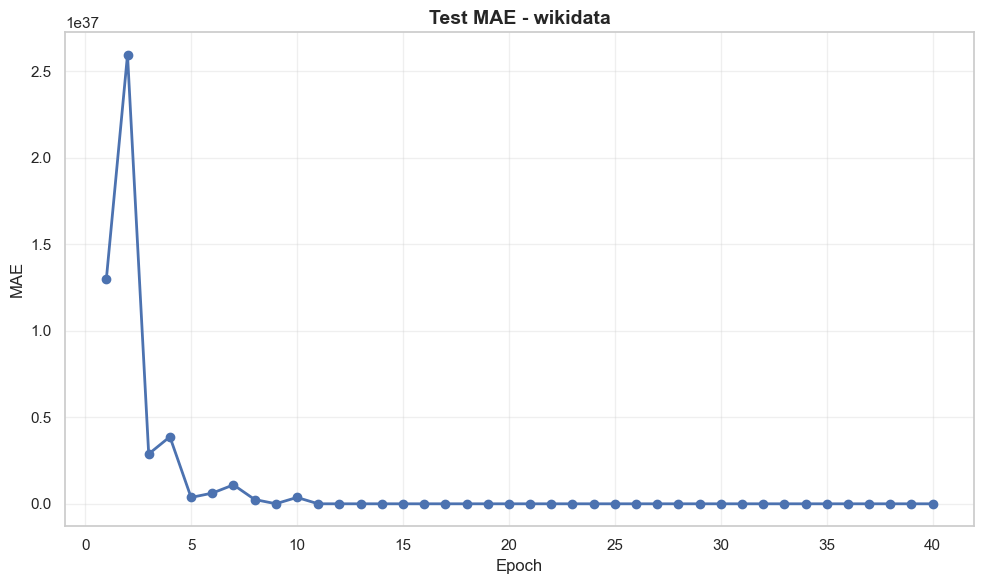

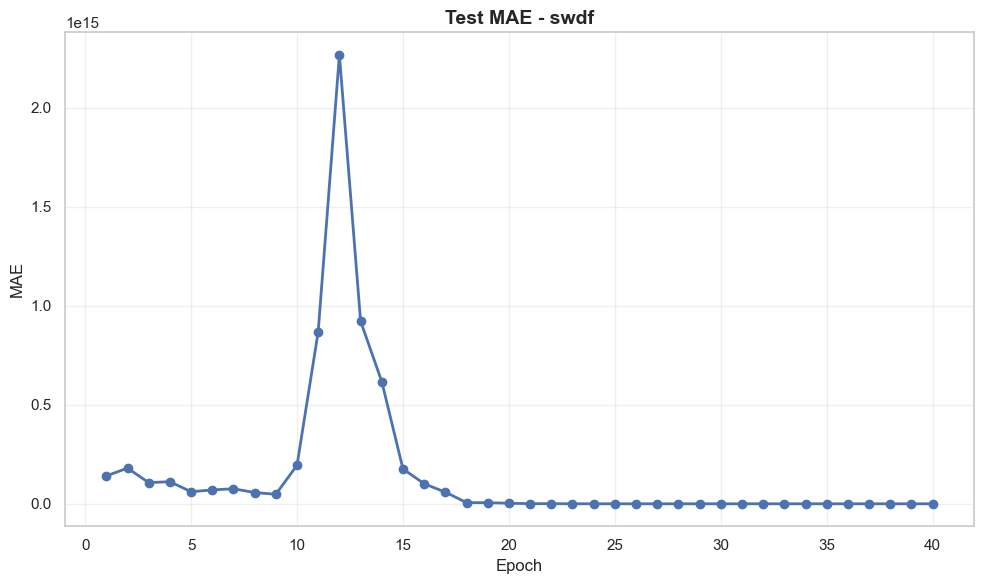

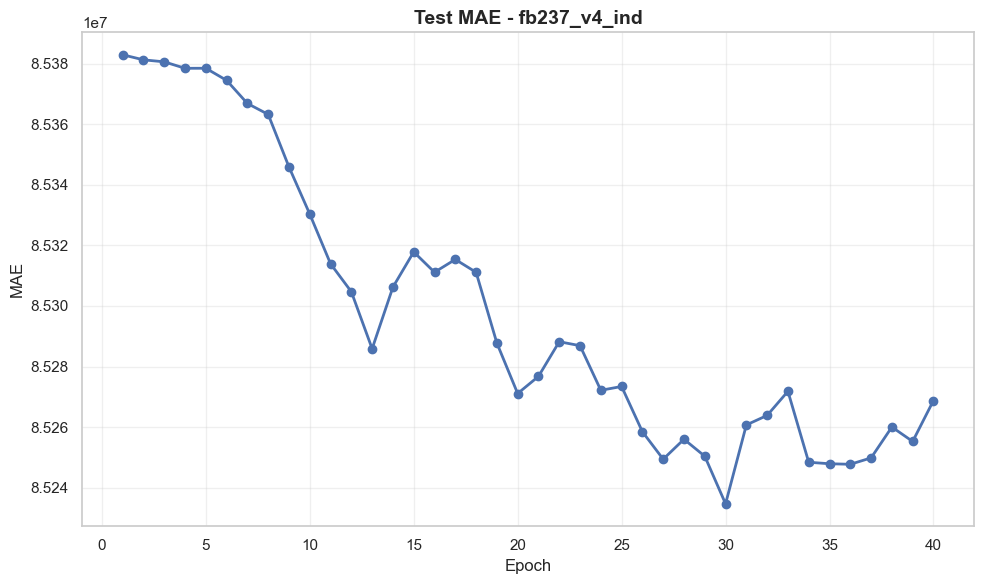

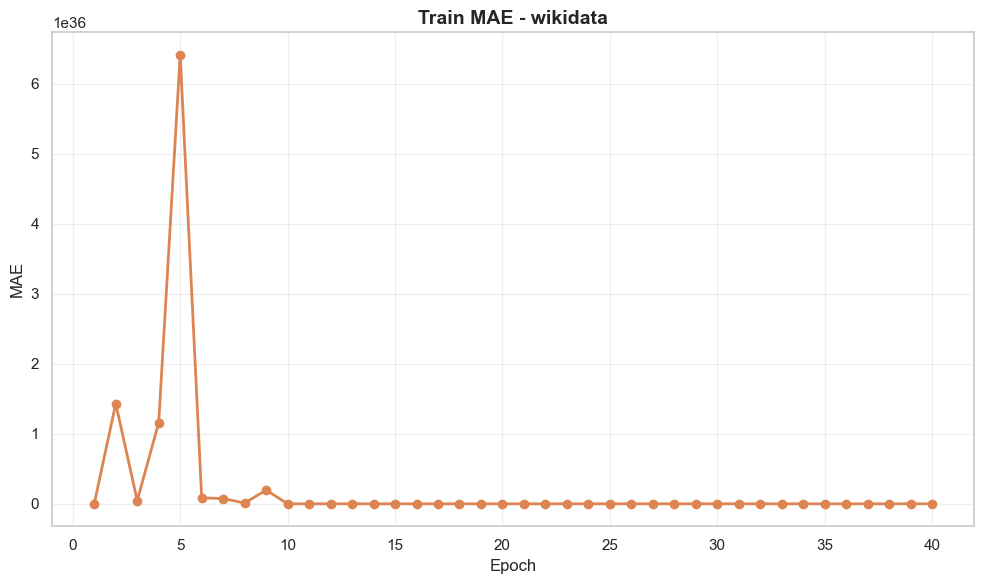

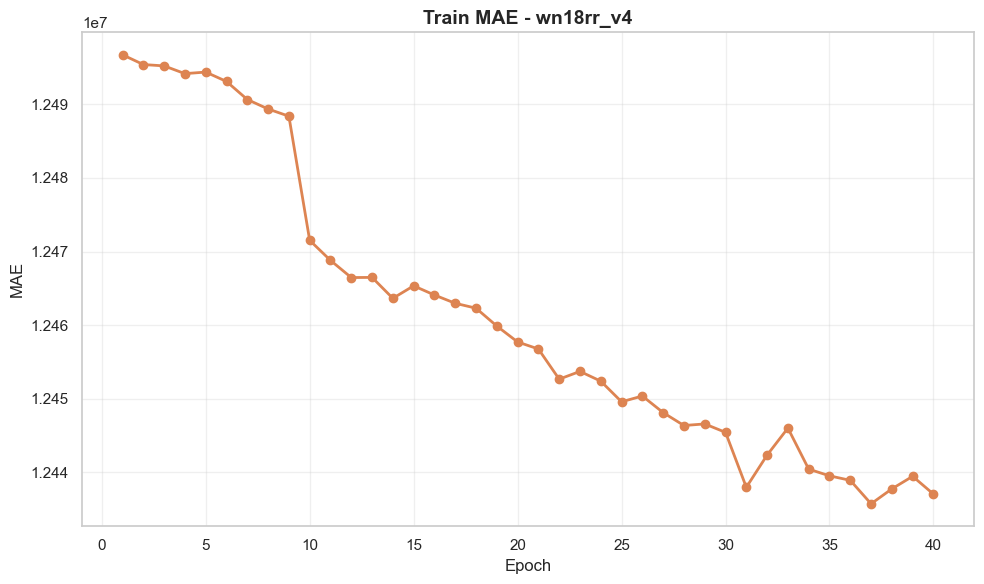

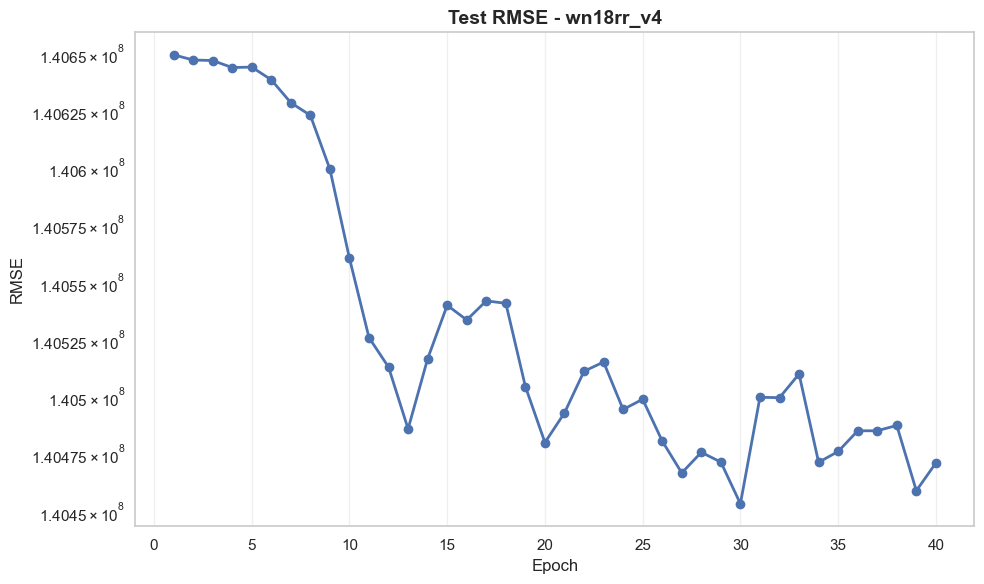

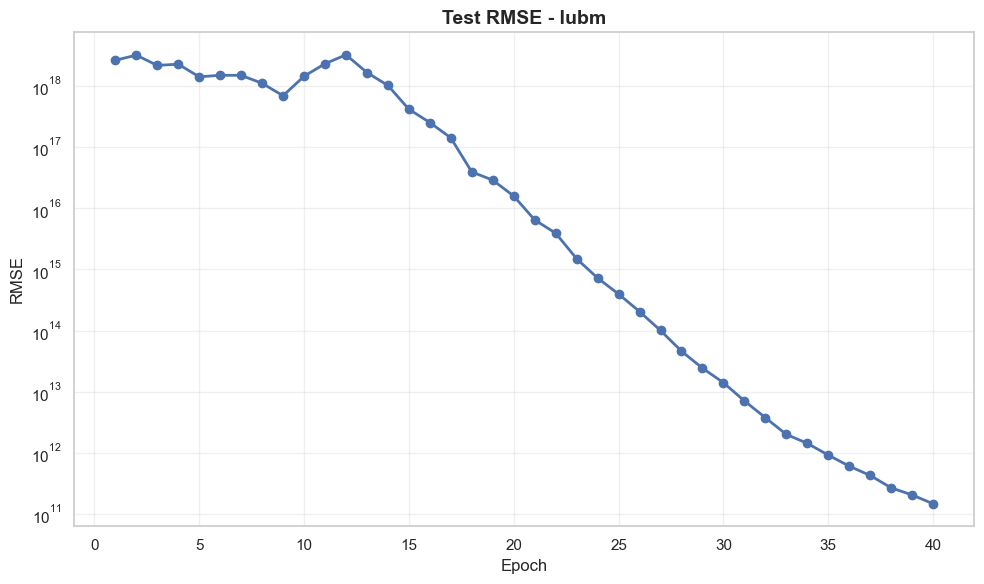

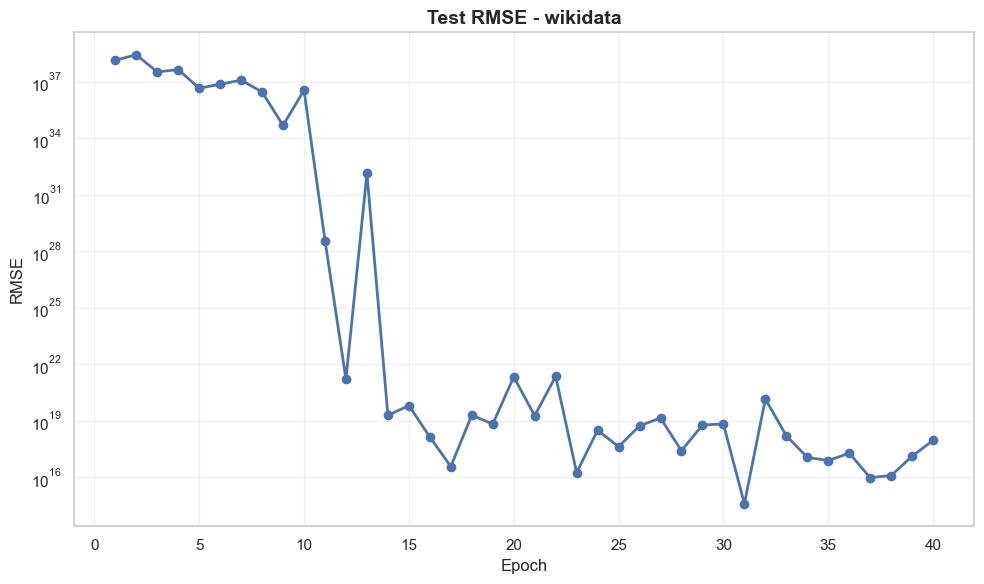

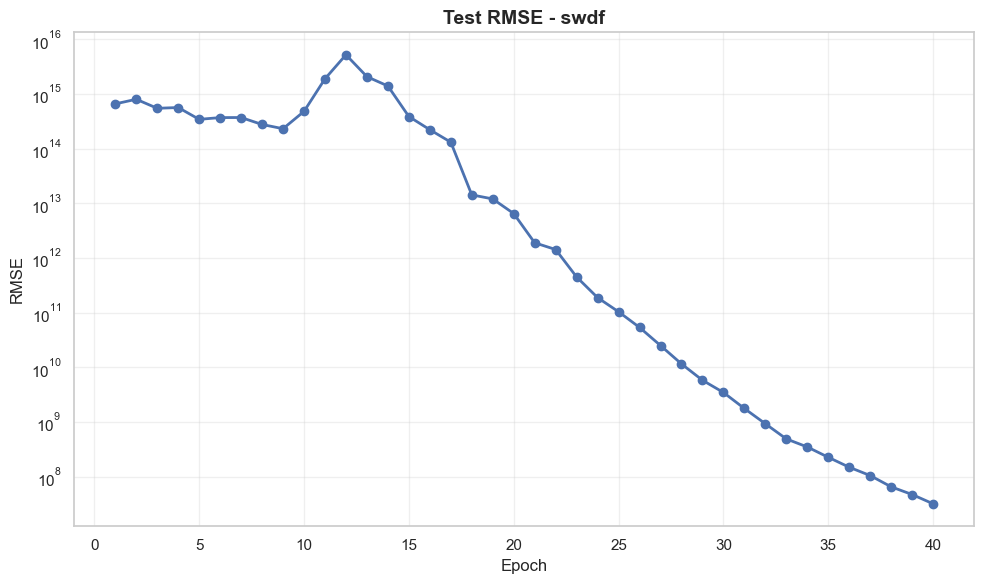

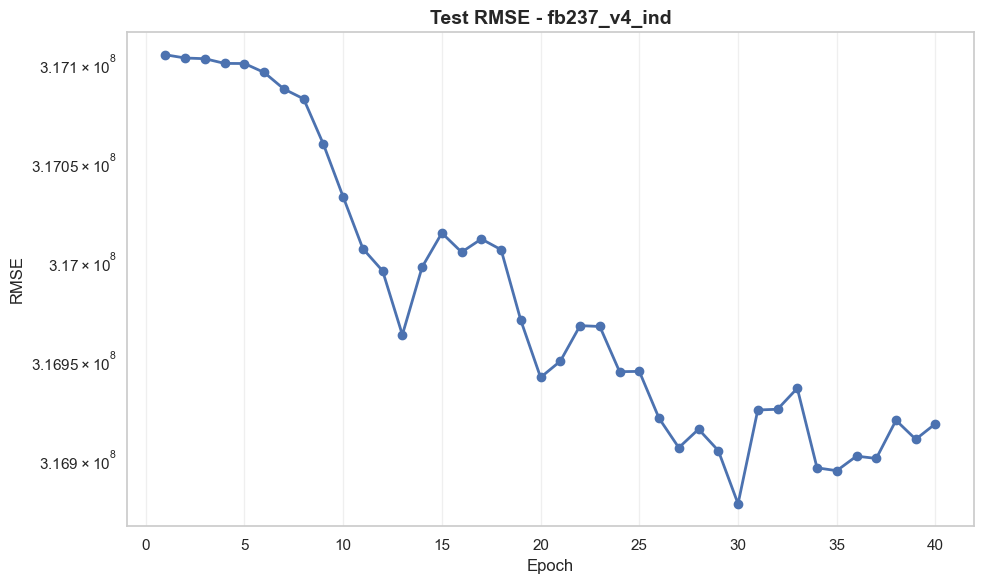

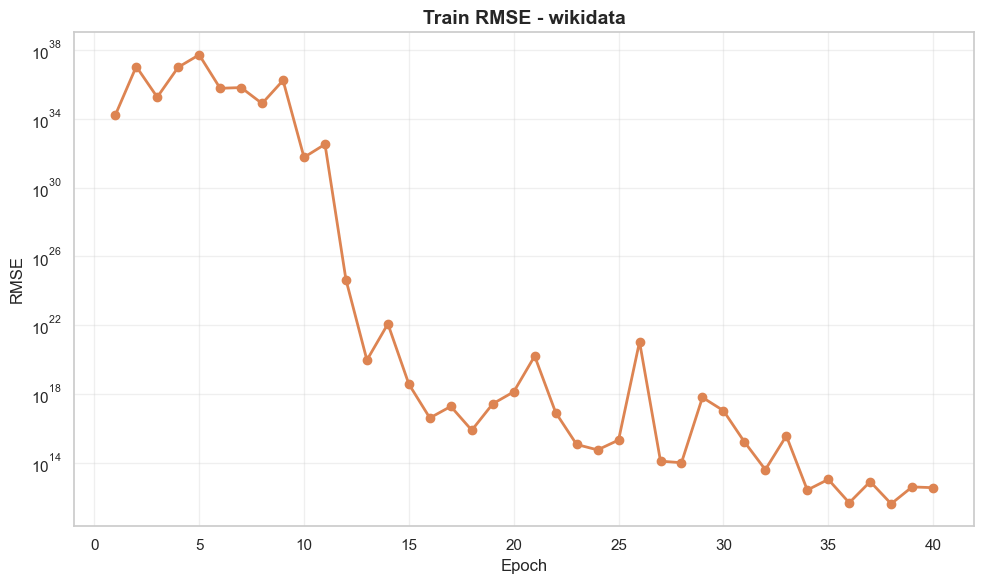

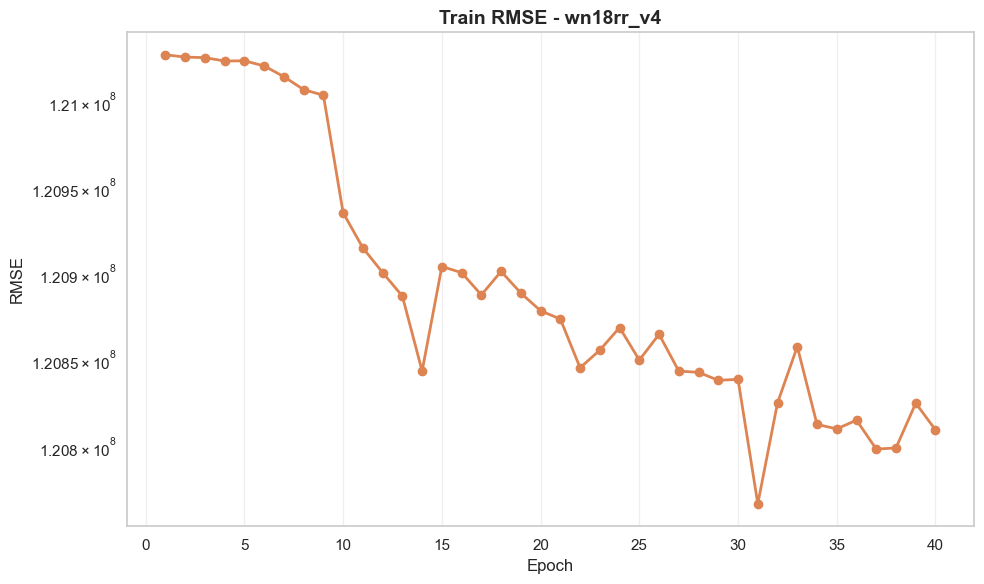

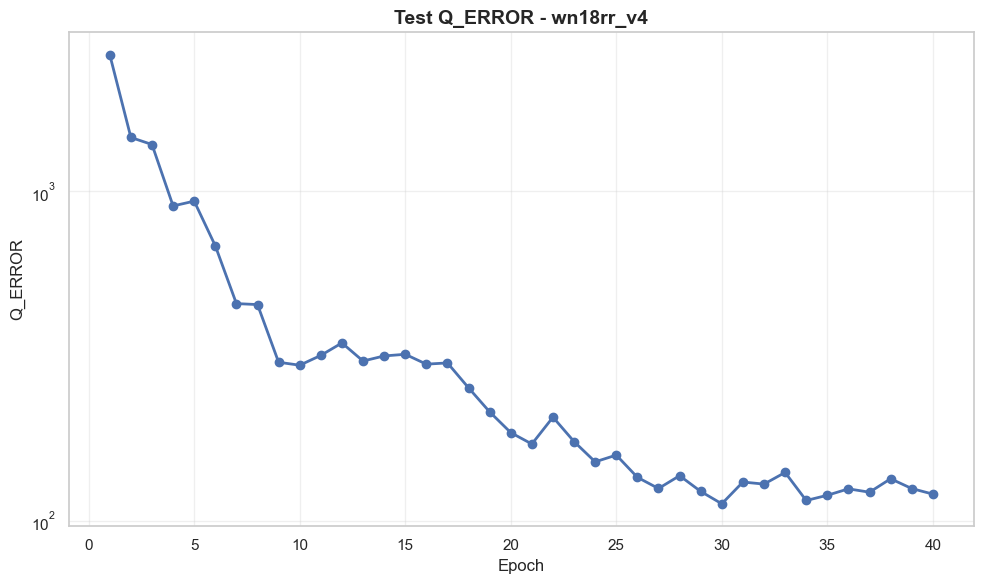

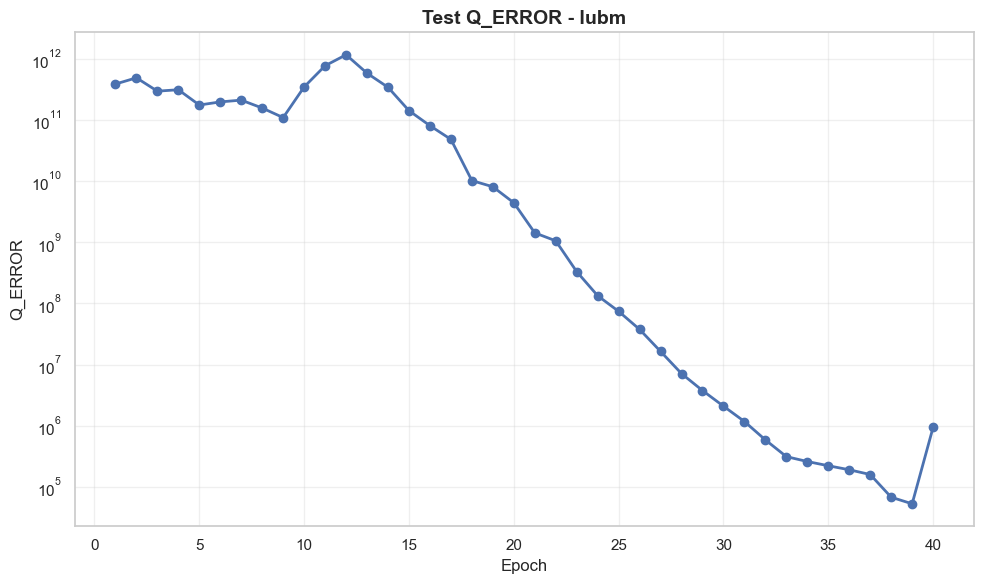

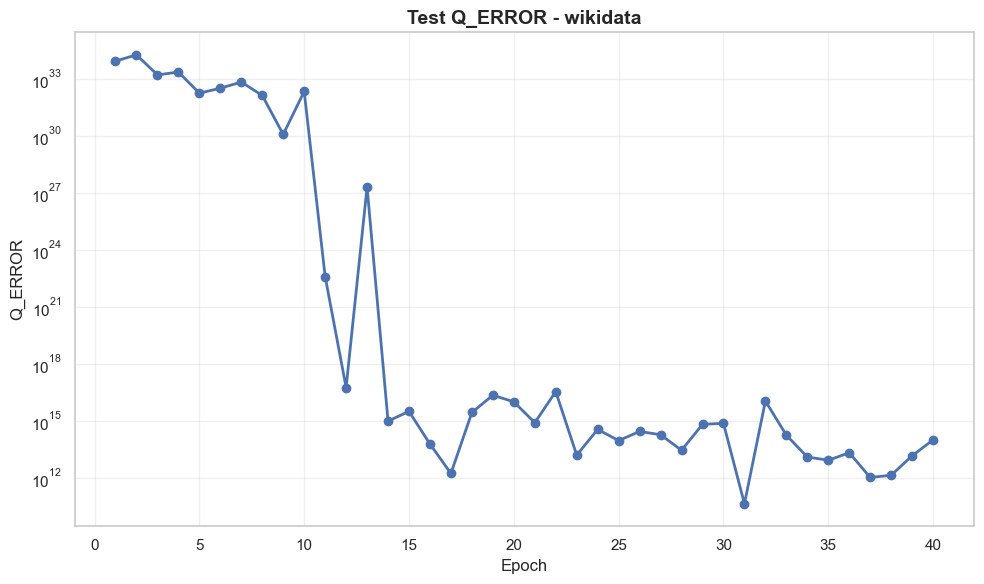

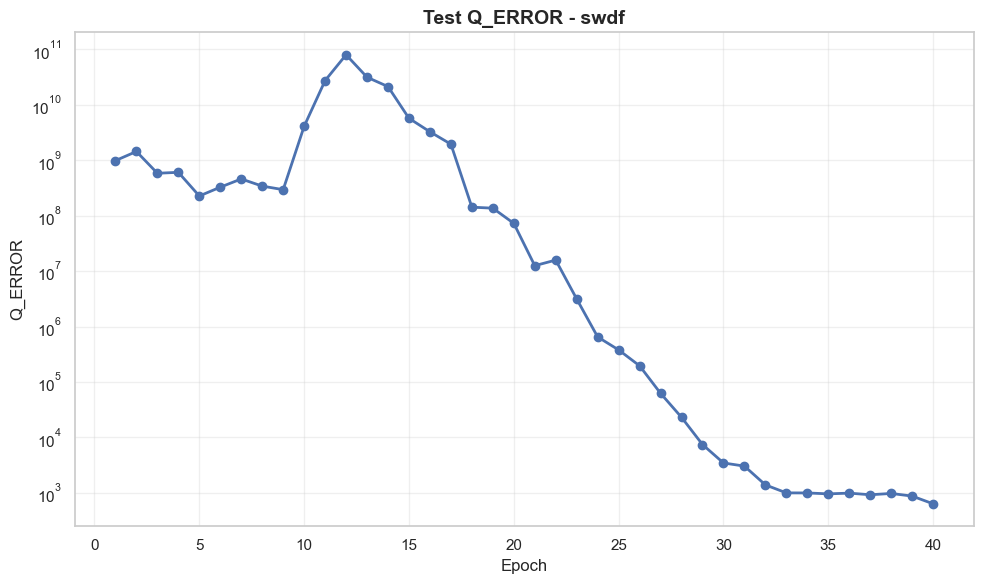

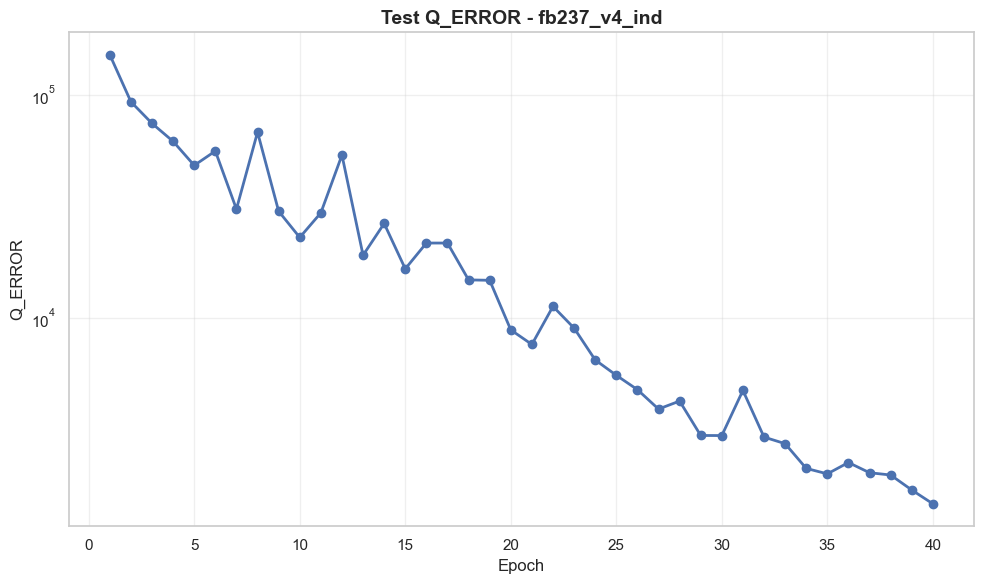

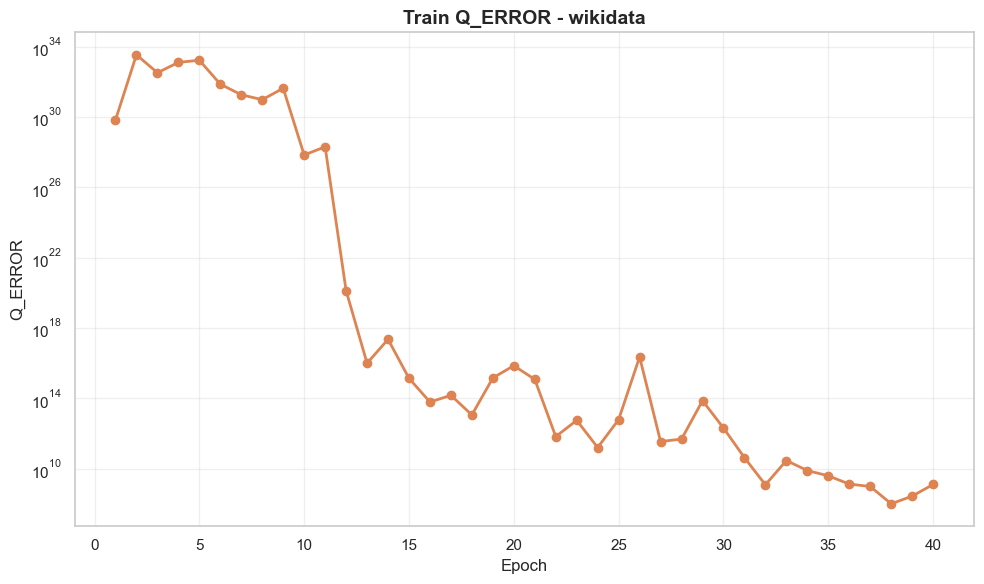

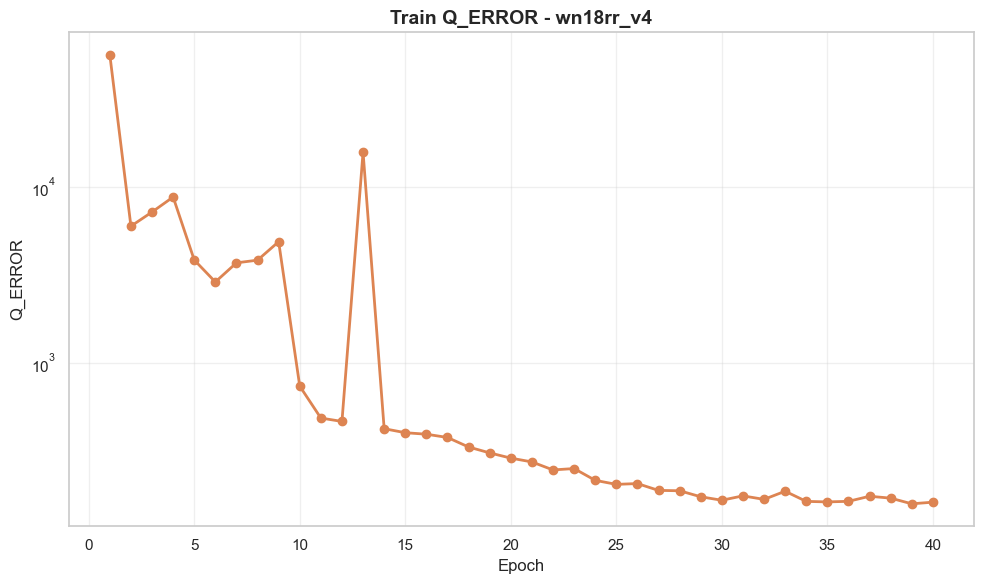

In [19]:
# Define metrics to plot
metrics = ['loss', 'mse', 'mae', 'rmse', 'q_error']

# Metrics that benefit from log scale due to large value ranges
log_scale_metrics = ['mse', 'rmse', 'q_error']

# Create plots for each metric and each dataset combination
for metric in metrics:
    # Test data - one figure per dataset
    for dataset in test_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = test_data[test_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6)
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Test {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()
    
    # Train data - one figure per dataset
    for dataset in train_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = train_data[train_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6, color='C1')
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Train {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()